# TP Machine Learning 2 - Prediccion de Satisfaccion de Pasajeros de Aerolinea

**Modulo 6 - Modelado Predictivo II: Tecnicas Avanzadas de Machine Learning**

**Curso:** Diplomatura en Ciencia de Datos y Analisis Avanzado

Este notebook contiene el desarrollo completo que respalda el informe. Todos los
resultados, tablas y figuras del informe se generan aca.

**Medicion de tiempos:** todos los modelos se entrenan en **un solo nucleo**
(`n_jobs=1`) para que la comparacion de costo computacional sea justa. La busqueda
de hiperparametros si usa todos los nucleos, porque no forma parte del tiempo
reportado.

**Optimizacion de hiperparametros:** se optimizan con `GridSearchCV` el Arbol, el
SVM y el Gradient Boosting, que son los tres modelos cuyo resultado depende mas de
esa eleccion. La Regresion Logistica, el KNN y el Random Forest quedan en su
configuracion estandar; esa asimetria juega en contra de ellos y esta declarada
como limitacion en el informe.

## 1. Problema y objetivo

Problema de **clasificacion binaria**: predecir si un pasajero de aerolinea queda
**insatisfecho** (`neutral or dissatisfied`) o **satisfecho** (`satisfied`) con el
servicio, a partir de datos demograficos, caracteristicas del vuelo y calificaciones
de distintos aspectos del servicio.

**Definicion de la clase positiva:** se codifica `1 = insatisfecho`. Esta decision no
es cosmetica: define que es un falso negativo. El objetivo de negocio es **detectar
pasajeros insatisfechos para poder intervenir**, por lo que el error costoso es dejar
pasar a un insatisfecho sin detectarlo. Con esta codificacion, ese error es un falso
negativo y queda capturado por el **recall**.

## 2. Importacion de librerias

In [ ]:
# Manipulacion de datos
import pandas as pd
import numpy as np
import time  # para medir el costo computacional de cada modelo

# Visualizacion
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y validacion
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     GridSearchCV, StratifiedKFold)
from sklearn.preprocessing import StandardScaler

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Metricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42  # semilla fija: resultados reproducibles

## 3. Carga del dataset

In [ ]:
# El dataset viene ya dividido en dos archivos por el proveedor.
train_df = pd.read_csv("train.csv")
test_df  = pd.read_csv("test.csv")

print("Dimensiones train:", train_df.shape)
print("Dimensiones test :", test_df.shape)
train_df.head(3)

Dimensiones train: (103904, 25)
Dimensiones test : (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied


## 4. Analisis exploratorio (EDA)

Revisamos estructura, tipos, valores faltantes y balance de la variable objetivo.

In [ ]:
print("Columnas:", list(train_df.columns), "\n")
print("Valores nulos por columna (solo las que tienen):")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0], "\n")
print("Nulos en test:")
print(test_df.isnull().sum()[test_df.isnull().sum() > 0])

Columnas: ['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction'] 

Valores nulos por columna (solo las que tienen):
Arrival Delay in Minutes    310
dtype: int64 

Nulos en test:
Arrival Delay in Minutes    83
dtype: int64


Distribucion de la variable objetivo (%):
satisfaction
neutral or dissatisfied    56.7
satisfied                  43.3
Name: proportion, dtype: float64


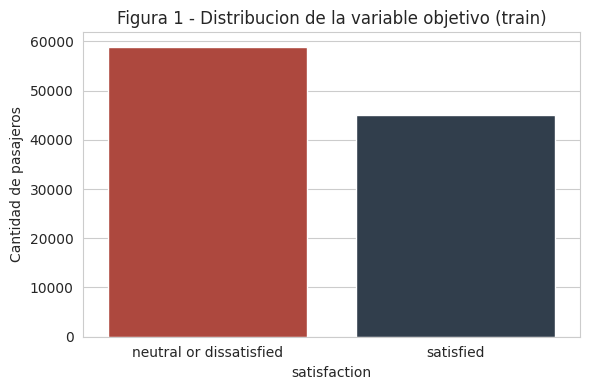

In [ ]:
# Balance de la variable objetivo: condiciona que metrica conviene usar.
dist = train_df['satisfaction'].value_counts(normalize=True) * 100
print("Distribucion de la variable objetivo (%):")
print(dist.round(1))

plt.figure(figsize=(6, 4))
vc = train_df['satisfaction'].value_counts()
sns.barplot(x=vc.index, y=vc.values, hue=vc.index,
            palette=['#c0392b', '#2c3e50'], legend=False)
plt.title('Figura 1 - Distribucion de la variable objetivo (train)')
plt.xlabel('satisfaction'); plt.ylabel('Cantidad de pasajeros')
plt.tight_layout(); plt.savefig('fig1_distribucion_objetivo.png', dpi=150); plt.show()

## 5. Feature engineering

Pasos aplicados, identicos en train y en test:

1. **Eliminar `Unnamed: 0` e `id`**: son identificadores, no aportan senal predictiva.
2. **Eliminar filas con nulos** en `Arrival Delay in Minutes` (~0,3% del total).
3. **Codificar la variable objetivo**: `1 = neutral or dissatisfied` (insatisfecho,
   clase positiva), `0 = satisfied`.
4. **One-Hot Encoding** de todas las categoricas con `pd.get_dummies(drop_first=True)`.
   Se usa el mismo mecanismo para las binarias y para `Class` (3 categorias), para no
   imponer un orden que no existe. Al usar `get_dummies` no se ajusta ningun
   codificador sobre el set de test.
5. **Estandarizacion** con `StandardScaler`, ajustado **solo con train**. Es necesaria
   para Regresion Logistica, KNN y SVM, que son sensibles a la escala. Los modelos de
   arboles usan los datos sin estandarizar (no lo necesitan).

In [ ]:
CATEGORICAS = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

def preparar_datos(df):
    df = df.copy()
    df = df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')   # 1
    df = df.dropna()   # 2 - los unicos nulos estan en Arrival Delay in Minutes
    df['satisfaction'] = df['satisfaction'].map(                  # 3
        {'neutral or dissatisfied': 1, 'satisfied': 0})
    df = pd.get_dummies(df, columns=CATEGORICAS, drop_first=True) # 4
    return df

train_prep = preparar_datos(train_df)
test_prep  = preparar_datos(test_df)

X_train = train_prep.drop(columns=['satisfaction'])
y_train = train_prep['satisfaction']
X_test  = test_prep.drop(columns=['satisfaction']).reindex(
    columns=X_train.columns, fill_value=0)   # alineamos columnas por las dudas
y_test  = test_prep['satisfaction']

print("Predictoras finales (", X_train.shape[1], "):", list(X_train.columns))
print("\nX_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporcion de insatisfechos -> train:", round(y_train.mean(), 4),
      "| test:", round(y_test.mean(), 4))

Predictoras finales ( 23 ): ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender_Male', 'Customer Type_disloyal Customer', 'Type of Travel_Personal Travel', 'Class_Eco', 'Class_Eco Plus']

X_train: (103594, 23) | X_test: (25893, 23)
Proporcion de insatisfechos -> train: 0.5666 | test: 0.5611


In [ ]:
# 5. Estandarizacion: el scaler se ajusta SOLO con train para no filtrar
# informacion del test al entrenamiento.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print("Datos estandarizados. Shape:", X_train_scaled.shape)

Datos estandarizados. Shape: (103594, 23)


## 6. Metrica de evaluacion

La variable objetivo esta **razonablemente balanceada** (56,7% / 43,3%), asi que la
**Accuracy** no es enganosa y se reporta como referencia.

Sin embargo, la metrica **principal es el F1-score sobre la clase "insatisfecho"**,
por dos razones:

1. **El costo del error no es simetrico.** Dejar pasar a un pasajero insatisfecho
   (falso negativo) implica perder la oportunidad de retenerlo; marcar de mas a uno
   satisfecho (falso positivo) solo cuesta una accion comercial innecesaria. Por eso
   se reporta tambien el **recall**, que mide directamente que proporcion de
   insatisfechos logramos detectar.
2. **El F1 no premia a un modelo que se incline por la clase mayoritaria**, cosa que
   la accuracy si puede tolerar.

Se usa F1 y no una metrica puramente de recall porque un modelo que marque a todos
como insatisfechos tendria recall perfecto y seria inutil: el F1 penaliza esa
degradacion de la precision. El recall se usa como criterio de desempate cuando dos
modelos tienen F1 equivalente.

## 7. Entrenamiento y evaluacion

La funcion siguiente entrena, mide **tiempo de entrenamiento y de prediccion** y
evalua sobre el set de test completo.

Medir tambien el tiempo de prediccion es importante: hay modelos que entrenan casi
instantaneamente pero son caros al predecir (KNN), y en produccion la prediccion es
la operacion que se repite.

In [ ]:
resultados, predicciones, modelos_entrenados = [], {}, {}

# Calcula las metricas de un modelo ya entrenado y las guarda en la tabla comun.
def registrar(nombre, modelo, y_pred, t_fit, t_pred, yte=None, nota=''):
    yte = y_test if yte is None else yte
    fila = {'Modelo': nombre,
            'Accuracy':  accuracy_score(yte, y_pred),
            'Precision': precision_score(yte, y_pred),
            'Recall':    recall_score(yte, y_pred),
            'F1-score':  f1_score(yte, y_pred),
            'Tiempo_entren_seg': t_fit,
            'Tiempo_predic_seg': t_pred,
            'Nota': nota}
    resultados.append(fila)
    predicciones[nombre] = y_pred
    modelos_entrenados[nombre] = modelo
    print(f"--- {nombre} ---")
    print(f"Accuracy {fila['Accuracy']:.4f} | Precision {fila['Precision']:.4f} | "
          f"Recall {fila['Recall']:.4f} | F1 {fila['F1-score']:.4f}")
    print(f"Tiempo entrenamiento {t_fit:.2f}s | Tiempo prediccion {t_pred:.2f}s\n")
    return modelo

def entrenar_y_evaluar(nombre, modelo, Xtr, Xte, ytr=None, yte=None, nota=''):
    ytr = y_train if ytr is None else ytr
    t0 = time.perf_counter(); modelo.fit(Xtr, ytr)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred = modelo.predict(Xte)
    t_pred = time.perf_counter() - t0
    return registrar(nombre, modelo, y_pred, t_fit, t_pred, yte=yte, nota=nota)

### 7.1 Modelo 1 - Regresion Logistica *(obligatorio: visto en Machine Learning 1)*

Sin optimizar: configuracion estandar.

In [ ]:
# Modelo lineal. Sirve como linea de base: si un modelo complejo no le gana
# claramente, no se justifica su costo. Usa datos estandarizados.
entrenar_y_evaluar(
    'Regresion Logistica',
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, n_jobs=1),
    X_train_scaled, X_test_scaled)

--- Regresion Logistica ---
Accuracy 0.8718 | Precision 0.8736 | Recall 0.9021 | F1 0.8876
Tiempo entrenamiento 0.17s | Tiempo prediccion 0.00s



,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### 7.2 Modelo 2 - KNN *(visto en Machine Learning 1)*

Sin optimizar: k=5, el valor por defecto.

In [ ]:
# Modelo "perezoso": no aprende parametros, guarda el set de entrenamiento.
# Por eso el entrenamiento es instantaneo y el costo se paga al predecir.
entrenar_y_evaluar(
    'KNN',
    KNeighborsClassifier(n_neighbors=5, n_jobs=1),
    X_train_scaled, X_test_scaled)

--- KNN ---
Accuracy 0.9277 | Precision 0.9136 | Recall 0.9621 | F1 0.9372
Tiempo entrenamiento 0.02s | Tiempo prediccion 8.16s



,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,1


### 7.3 Modelo 3 - Arbol de Decision *(optimizado con GridSearchCV)*

In [ ]:
# Los arboles no necesitan estandarizacion: usamos los datos crudos.
param_arbol = {'criterion': ['gini', 'entropy'], 'max_depth': [None, 10, 20, 30]}
grid_arbol = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                          param_arbol, cv=3, scoring='f1', n_jobs=-1)
grid_arbol.fit(X_train, y_train)
print("Mejores hiperparametros del Arbol:", grid_arbol.best_params_, "\n")

entrenar_y_evaluar(
    'Arbol de Decision',
    DecisionTreeClassifier(random_state=RANDOM_STATE, **grid_arbol.best_params_),
    X_train, X_test)

Mejores hiperparametros del Arbol: {'criterion': 'entropy', 'max_depth': 20} 



--- Arbol de Decision ---
Accuracy 0.9517 | Precision 0.9520 | Recall 0.9625 | F1 0.9572
Tiempo entrenamiento 0.42s | Tiempo prediccion 0.00s



,criterion,'entropy'
,splitter,'best'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


### 7.4 Modelo 4 - SVM con kernel RBF

El SVM con kernel RBF tiene un costo de entrenamiento que crece de forma
**superlineal** con la cantidad de filas. En lugar de asumirlo, lo **medimos**:
entrenamos el mismo SVM con muestras estratificadas crecientes y observamos como
evolucionan el tiempo y el F1. El exponente empirico que sale de esa curva es
**n^2,2**; extrapolado, el train completo costaria del orden de tres minutos. Aun
asi el modelo final se queda con la muestra de 40.000 (38,6% del train), y eso
queda declarado como limite del trabajo: la extrapolacion del costo es confiable,
la del F1 no lo es porque la metrica satura.

In [ ]:
# Busqueda de hiperparametros sobre una muestra chica (el grid es caro).
X_g, _, y_g, _ = train_test_split(X_train_scaled, y_train, train_size=10000,
                                  stratify=y_train, random_state=RANDOM_STATE)
grid_svm = GridSearchCV(SVC(kernel='rbf', random_state=RANDOM_STATE),
                        {'C': [1, 10], 'gamma': ['scale', 0.1]},
                        cv=3, scoring='f1', n_jobs=-1)
grid_svm.fit(X_g, y_g)
print("Mejores hiperparametros del SVM:", grid_svm.best_params_)

Mejores hiperparametros del SVM: {'C': 10, 'gamma': 'scale'}


In [ ]:
# Curva de costo: como escala el SVM al crecer la muestra de entrenamiento.
# El ajuste con n=40.000 es ademas el modelo final, asi que se reutiliza
# (no se vuelve a entrenar).
curva_svm = []
N_FINAL_SVM = 40000

for n in [5000, 15000, N_FINAL_SVM]:
    X_s, _, y_s, _ = train_test_split(X_train_scaled, y_train, train_size=n,
                                      stratify=y_train, random_state=RANDOM_STATE)
    svm_n = SVC(kernel='rbf', random_state=RANDOM_STATE, **grid_svm.best_params_)
    t0 = time.perf_counter(); svm_n.fit(X_s, y_s); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred_n = svm_n.predict(X_test_scaled)
    t_pred = time.perf_counter() - t0
    f1_n = f1_score(y_test, y_pred_n)
    curva_svm.append({'n': n, 'tiempo_seg': t_fit, 'f1_test': f1_n,
                      'vectores_soporte': int(svm_n.n_support_.sum())})
    print(f"n={n:6d} | fit {t_fit:7.2f}s | F1 test {f1_n:.4f} | "
          f"vectores de soporte {svm_n.n_support_.sum()}")
    if n == N_FINAL_SVM:      # este es el modelo final: registramos sus metricas
        registrar('SVM (RBF)', svm_n, y_pred_n, t_fit, t_pred,
                  nota=f'entrenado con muestra estratificada de {N_FINAL_SVM} filas '
                       f'({N_FINAL_SVM/len(y_train):.1%} del train)')

df_curva = pd.DataFrame(curva_svm)
print(df_curva.round(4).to_string(index=False))

n=  5000 | fit    0.22s | F1 test 0.9407 | vectores de soporte 1176


n= 15000 | fit    2.01s | F1 test 0.9522 | vectores de soporte 2906


n= 40000 | fit   21.84s | F1 test 0.9603 | vectores de soporte 6229
--- SVM (RBF) ---
Accuracy 0.9550 | Precision 0.9517 | Recall 0.9690 | F1 0.9603
Tiempo entrenamiento 21.84s | Tiempo prediccion 5.91s

    n  tiempo_seg  f1_test  vectores_soporte
 5000      0.2248   0.9407              1176
15000      2.0067   0.9522              2906
40000     21.8364   0.9603              6229


### 7.5 Modelo 5 - Random Forest *(ensamble en paralelo, bagging)*

Sin optimizar: 300 arboles con los parametros por defecto del resto.

In [ ]:
# 300 arboles con submuestreo de variables. n_jobs=1 para que el tiempo sea
# comparable con el del resto de los modelos.
entrenar_y_evaluar(
    'Random Forest',
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    X_train, X_test)

--- Random Forest ---
Accuracy 0.9632 | Precision 0.9565 | Recall 0.9789 | F1 0.9676
Tiempo entrenamiento 25.21s | Tiempo prediccion 0.71s



,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 7.6 Modelo 6 - Gradient Boosting *(ensamble secuencial, optimizado)*

Se optimizan sus hiperparametros con GridSearchCV, igual que el Arbol y el SVM.
Compararlo con valores por defecto contra modelos ajustados seria una comparacion
sesgada.

In [ ]:
# El grid se hace sobre una muestra por costo; el modelo final se entrena
# con el train completo.
X_gb, _, y_gb, _ = train_test_split(X_train, y_train, train_size=8000,
                                    stratify=y_train, random_state=RANDOM_STATE)
grid_gb = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
                       {'n_estimators': [100, 200], 'max_depth': [3, 5]},
                       cv=3, scoring='f1', n_jobs=-1)
grid_gb.fit(X_gb, y_gb)
print("Mejores hiperparametros del Gradient Boosting:", grid_gb.best_params_, "\n")

entrenar_y_evaluar(
    'Gradient Boosting',
    GradientBoostingClassifier(random_state=RANDOM_STATE, **grid_gb.best_params_),
    X_train, X_test)

Mejores hiperparametros del Gradient Boosting: {'max_depth': 5, 'n_estimators': 200} 



--- Gradient Boosting ---
Accuracy 0.9625 | Precision 0.9559 | Recall 0.9782 | F1 0.9669
Tiempo entrenamiento 40.33s | Tiempo prediccion 0.09s



,loss,'log_loss'
,learning_rate,0.1
,n_estimators,200
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,5
,min_impurity_decrease,0.0
,init,None


## 8. Validacion cruzada (5-fold)

La validacion cruzada se corre sobre una **unica muestra comun de 10.000 registros**
para los seis modelos: el SVM no puede correr sobre el train completo, y comparar su
CV contra la de modelos validados con 103.594 filas seria mezclar cosas distintas.

**Como leerla.** Cada fold entrena con 8.000 filas, trece veces menos que el modelo
final. Eso tiene dos consecuencias: sus valores absolutos no son comparables contra
la columna de test, y **el orden que da tampoco transfiere de forma automatica** al
regimen de entrenamiento real. La curva del SVM de la seccion anterior lo muestra:
solo cambiar el tamano de muestra le mueve el F1 en 0,0196, mas que cualquier
diferencia entre los dos primeros modelos. Por eso la CV se usa para **verificar
estabilidad** y como evidencia secundaria, no como criterio de desempate.

In [ ]:
idx_cv, _ = train_test_split(np.arange(len(y_train)), train_size=10000,
                             stratify=y_train, random_state=RANDOM_STATE)
X_cv_raw = X_train.iloc[idx_cv]
X_cv_sc  = X_train_scaled[idx_cv]
y_cv     = y_train.iloc[idx_cv]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

modelos_cv = {
 'Regresion Logistica': (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_cv_sc),
 'KNN':                 (KNeighborsClassifier(n_neighbors=5), X_cv_sc),
 'Arbol de Decision':   (DecisionTreeClassifier(random_state=RANDOM_STATE,
                         **grid_arbol.best_params_), X_cv_raw),
 'SVM (RBF)':           (SVC(kernel='rbf', random_state=RANDOM_STATE,
                         **grid_svm.best_params_), X_cv_sc),
 'Random Forest':       (RandomForestClassifier(n_estimators=300,
                         random_state=RANDOM_STATE), X_cv_raw),
 'Gradient Boosting':   (GradientBoostingClassifier(random_state=RANDOM_STATE,
                         **grid_gb.best_params_), X_cv_raw),
}

cv_scores = {}
for nombre, (modelo, X_) in modelos_cv.items():
    s = cross_val_score(modelo, X_, y_cv, cv=cv, scoring='f1', n_jobs=-1)
    cv_scores[nombre] = (s.mean(), s.std())
    print(f"{nombre:22s} -> F1 CV = {s.mean():.4f} (+/- {s.std():.4f})")

Regresion Logistica    -> F1 CV = 0.8901 (+/- 0.0048)


KNN                    -> F1 CV = 0.9211 (+/- 0.0013)


Arbol de Decision      -> F1 CV = 0.9364 (+/- 0.0036)


SVM (RBF)              -> F1 CV = 0.9431 (+/- 0.0030)


Random Forest          -> F1 CV = 0.9514 (+/- 0.0049)


Gradient Boosting      -> F1 CV = 0.9606 (+/- 0.0033)


## 9. Tabla comparativa de resultados

In [ ]:
df_resultados = pd.DataFrame(resultados).set_index('Modelo')
df_resultados['F1_CV_medio'] = [cv_scores[m][0] for m in df_resultados.index]
df_resultados['F1_CV_desvio'] = [cv_scores[m][1] for m in df_resultados.index]
df_resultados = df_resultados.sort_values('F1-score', ascending=False)
df_resultados.to_csv('resultados_modelos.csv')

df_resultados.drop(columns=['Nota']).round(4)

,Accuracy,Precision,Recall,F1-score,Tiempo_entren_seg,Tiempo_predic_seg,F1_CV_medio,F1_CV_desvio
Modelo,,,,,,,,
Random Forest,0.9632,0.9565,0.9789,0.9676,25.2056,0.7147,0.9514,0.0049
Gradient Boosting,0.9625,0.9559,0.9782,0.9669,40.3299,0.0894,0.9606,0.0033
SVM (RBF),0.9550,0.9517,0.9690,0.9603,21.8364,5.9096,0.9431,0.0030
Arbol de Decision,0.9517,0.9520,0.9625,0.9572,0.4176,0.0039,0.9364,0.0036
KNN,0.9277,0.9136,0.9621,0.9372,0.0209,8.1582,0.9211,0.0013
Regresion Logistica,0.8718,0.8736,0.9021,0.8876,0.1745,0.0007,0.8901,0.0048


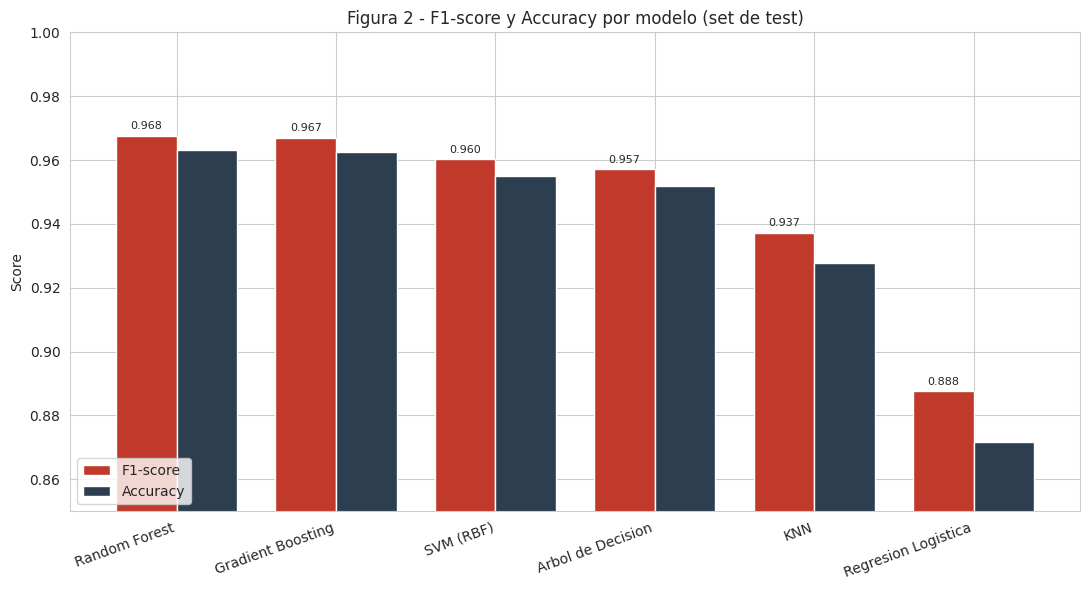

In [ ]:
# Figura 2 - F1 y Accuracy por modelo
orden = df_resultados.index.tolist()
x = np.arange(len(orden)); ancho = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - ancho/2, df_resultados['F1-score'], ancho, label='F1-score', color='#c0392b')
ax.bar(x + ancho/2, df_resultados['Accuracy'], ancho, label='Accuracy', color='#2c3e50')
ax.set_xticks(x); ax.set_xticklabels(orden, rotation=20, ha='right')
ax.set_ylim(0.85, 1.0); ax.set_ylabel('Score'); ax.legend(loc='lower left')
ax.set_title('Figura 2 - F1-score y Accuracy por modelo (set de test)')
for i, m in enumerate(orden):
    ax.text(i - ancho/2, df_resultados['F1-score'][m] + 0.002,
            f"{df_resultados['F1-score'][m]:.3f}", ha='center', fontsize=8)
plt.tight_layout(); plt.savefig('fig2_comparacion_metricas.png', dpi=150); plt.show()

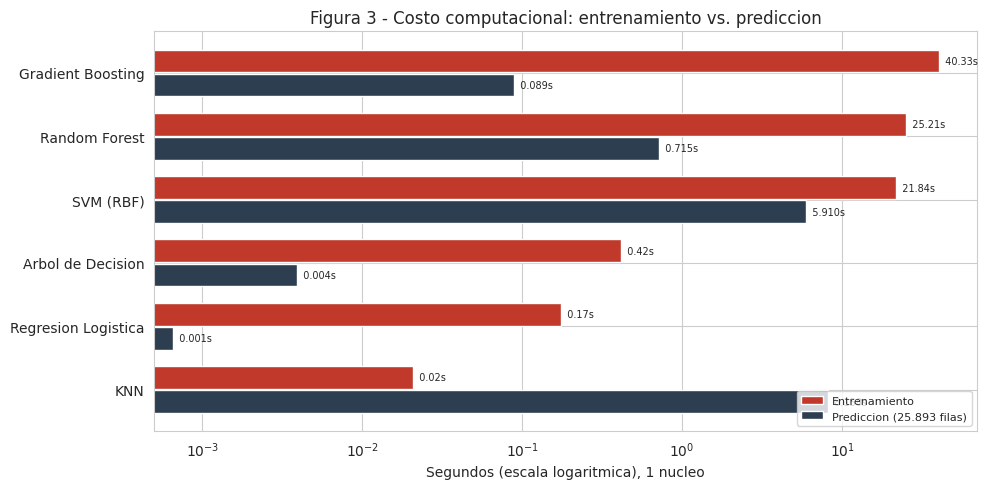

In [ ]:
# Figura 3 - Costo computacional: entrenamiento vs prediccion (escala log)
dft = df_resultados.sort_values('Tiempo_entren_seg')
yy = np.arange(len(dft))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(yy + 0.19, dft['Tiempo_entren_seg'], 0.36, color='#c0392b', label='Entrenamiento')
ax.barh(yy - 0.19, dft['Tiempo_predic_seg'], 0.36, color='#2c3e50', label='Prediccion (25.893 filas)')
ax.set_yticks(yy); ax.set_yticklabels(dft.index)
ax.set_xscale('log'); ax.set_xlabel('Segundos (escala logaritmica), 1 nucleo')
ax.set_title('Figura 3 - Costo computacional: entrenamiento vs. prediccion')
ax.legend(loc='lower right', fontsize=8)
for i, (t1, t2) in enumerate(zip(dft['Tiempo_entren_seg'], dft['Tiempo_predic_seg'])):
    ax.text(t1, i + 0.19, f'  {t1:.2f}s', va='center', fontsize=7)
    ax.text(t2, i - 0.19, f'  {t2:.3f}s', va='center', fontsize=7)
ax.set_xlim(left=5e-4)
plt.tight_layout(); plt.savefig('fig3_tiempos.png', dpi=150); plt.show()

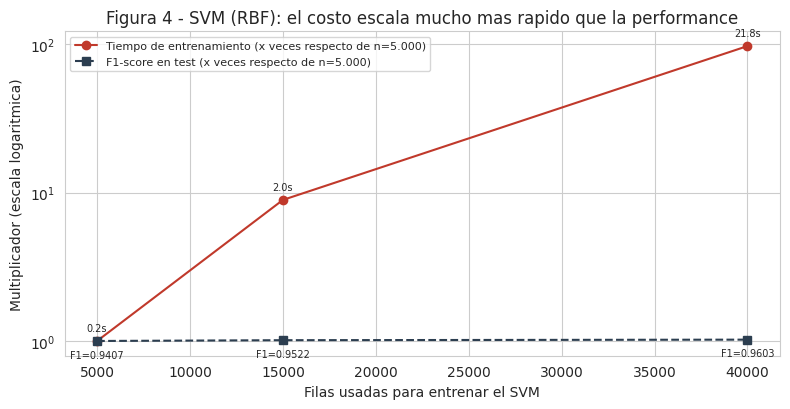

In [ ]:
# Figura 4 - Escalabilidad del SVM: costo vs. performance, normalizados
base_t = df_curva['tiempo_seg'].iloc[0]
base_f = df_curva['f1_test'].iloc[0]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(df_curva['n'], df_curva['tiempo_seg'] / base_t, 'o-', color='#c0392b',
        label='Tiempo de entrenamiento (x veces respecto de n=5.000)')
ax.plot(df_curva['n'], df_curva['f1_test'] / base_f, 's--', color='#2c3e50',
        label='F1-score en test (x veces respecto de n=5.000)')
ax.set_yscale('log'); ax.set_xlabel('Filas usadas para entrenar el SVM')
ax.set_ylabel('Multiplicador (escala logaritmica)')
ax.set_title('Figura 4 - SVM (RBF): el costo escala mucho mas rapido que la performance')
ax.legend(fontsize=8)
for _, r in df_curva.iterrows():
    ax.annotate(f"{r['tiempo_seg']:.1f}s", (r['n'], r['tiempo_seg']/base_t),
                textcoords="offset points", xytext=(0, 7), ha='center', fontsize=7)
    ax.annotate(f"F1={r['f1_test']:.4f}", (r['n'], r['f1_test']/base_f),
                textcoords="offset points", xytext=(0, -12), ha='center', fontsize=7)
plt.tight_layout(); plt.savefig('fig4_svm_escalabilidad.png', dpi=150); plt.show()

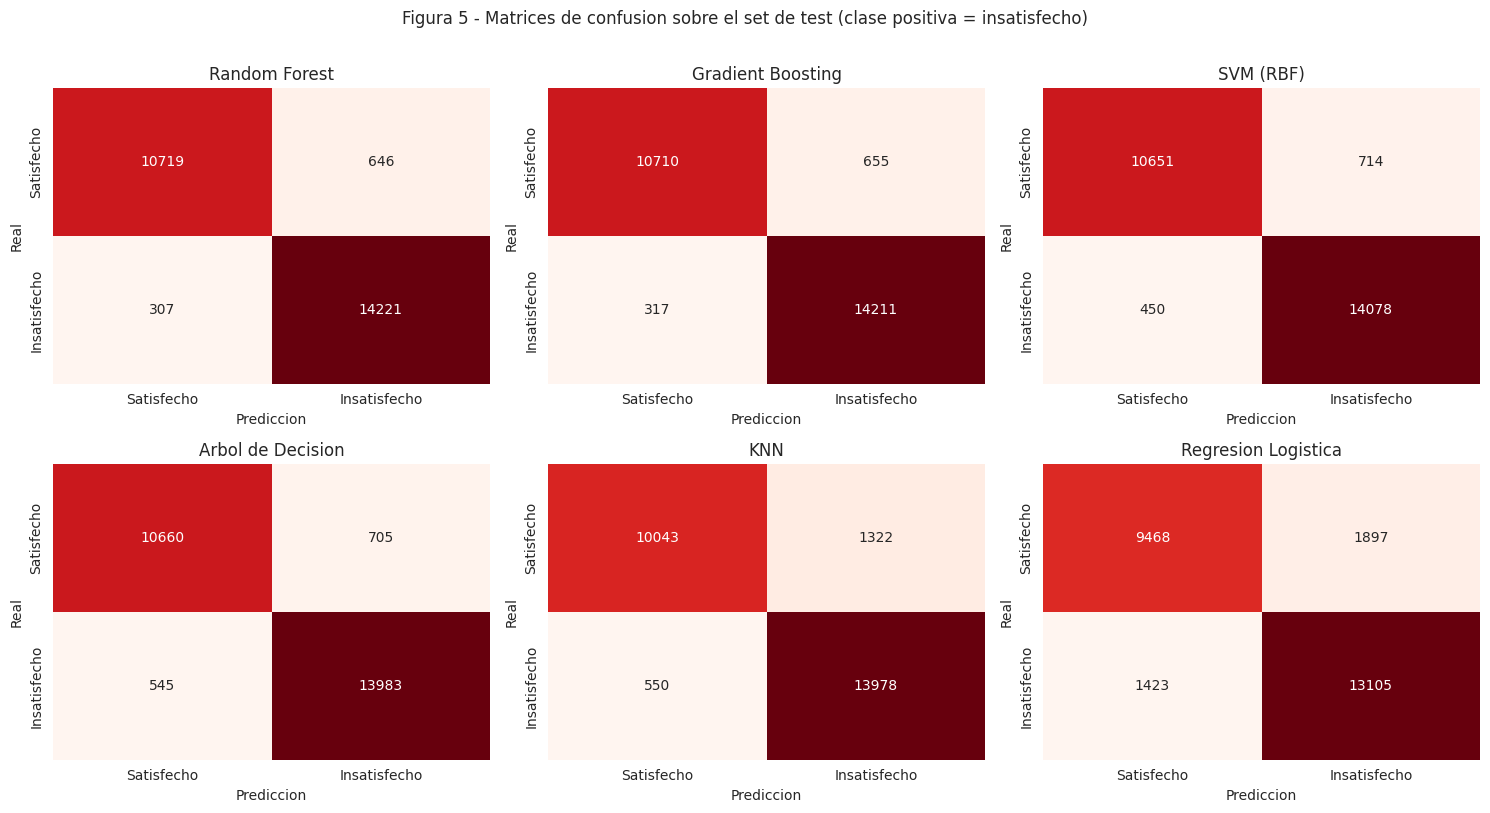

Insatisfechos no detectados (falsos negativos) por modelo:
  Random Forest          FN =   307  |  FP =   646  |  errores =   953
  Gradient Boosting      FN =   317  |  FP =   655  |  errores =   972
  SVM (RBF)              FN =   450  |  FP =   714  |  errores =  1164
  Arbol de Decision      FN =   545  |  FP =   705  |  errores =  1250
  KNN                    FN =   550  |  FP =  1322  |  errores =  1872
  Regresion Logistica    FN =  1423  |  FP =  1897  |  errores =  3320


In [ ]:
# Figura 5 - Matrices de confusion (clase positiva = insatisfecho)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, nombre in zip(axes.ravel(), orden):
    cm = confusion_matrix(y_test, predicciones[nombre])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax)
    ax.set_title(nombre); ax.set_xlabel('Prediccion'); ax.set_ylabel('Real')
    ax.set_xticklabels(['Satisfecho', 'Insatisfecho'])
    ax.set_yticklabels(['Satisfecho', 'Insatisfecho'])
plt.suptitle('Figura 5 - Matrices de confusion sobre el set de test '
             '(clase positiva = insatisfecho)', y=1.01)
plt.tight_layout(); plt.savefig('fig5_matrices_confusion.png', dpi=150,
                                bbox_inches='tight'); plt.show()

# Falsos negativos = insatisfechos NO detectados (el error costoso)
print("Insatisfechos no detectados (falsos negativos) por modelo:")
for m in orden:
    cm = confusion_matrix(y_test, predicciones[m])
    print(f"  {m:22s} FN = {cm[1,0]:5d}  |  FP = {cm[0,1]:5d}  |  errores = {cm[1,0]+cm[0,1]:5d}")

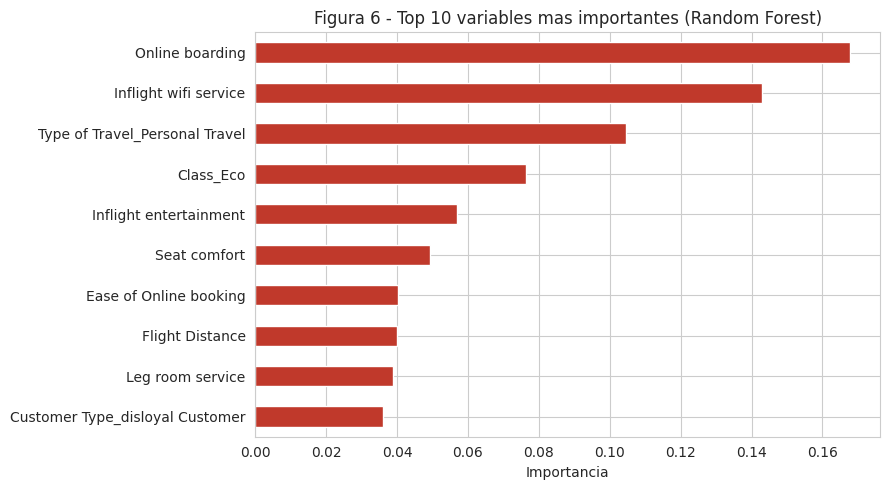

Online boarding                    0.1678
Inflight wifi service              0.1430
Type of Travel_Personal Travel     0.1046
Class_Eco                          0.0765
Inflight entertainment             0.0569
Seat comfort                       0.0493
Ease of Online booking             0.0402
Flight Distance                    0.0401
Leg room service                   0.0388
Customer Type_disloyal Customer    0.0360
dtype: float64

In [ ]:
# Figura 6 - Importancia de variables del mejor modelo
rf = modelos_entrenados['Random Forest']
importancias = pd.Series(rf.feature_importances_, index=X_train.columns)
top10 = importancias.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
top10.sort_values().plot(kind='barh', color='#c0392b')
plt.title('Figura 6 - Top 10 variables mas importantes (Random Forest)')
plt.xlabel('Importancia'); plt.tight_layout()
plt.savefig('fig6_importancia_variables.png', dpi=150); plt.show()
top10.round(4)

In [ ]:
# Resumen final
print("="*78)
print("RESUMEN (ordenado por F1-score sobre la clase 'insatisfecho', set de test)")
print("="*78)
print(df_resultados.drop(columns=['Nota']).round(4).to_string())
print("\nMejor modelo por F1 en test :", df_resultados.index[0])
print("Mejor modelo por F1 en CV   :",
      max(cv_scores, key=lambda k: cv_scores[k][0]))
print("="*78)

RESUMEN (ordenado por F1-score sobre la clase 'insatisfecho', set de test)
                     Accuracy  Precision  Recall  F1-score  Tiempo_entren_seg  Tiempo_predic_seg  F1_CV_medio  F1_CV_desvio
Modelo                                                                                                                     
Random Forest          0.9632     0.9565  0.9789    0.9676            25.2056             0.7147       0.9514        0.0049
Gradient Boosting      0.9625     0.9559  0.9782    0.9669            40.3299             0.0894       0.9606        0.0033
SVM (RBF)              0.9550     0.9517  0.9690    0.9603            21.8364             5.9096       0.9431        0.0030
Arbol de Decision      0.9517     0.9520  0.9625    0.9572             0.4176             0.0039       0.9364        0.0036
KNN                    0.9277     0.9136  0.9621    0.9372             0.0209             8.1582       0.9211        0.0013
Regresion Logistica    0.8718     0.8736  0.9021    0.887

## 10. Conclusiones

*(Desarrolladas en el informe. Sintesis:)*

- **Los ensambles de arboles ganan.** Random Forest y Gradient Boosting quedan
  empatados en test (F1 0,9676 y 0,9669) y ambos superan con claridad a la
  Regresion Logistica (0,8876): la frontera de decision no es lineal.
- **El modelo recomendado es el Gradient Boosting.** Empata con el Random Forest en
  la metrica: 953 errores contra 972 sobre 25.893 filas, diecinueve de diferencia.
  Como no hay desempate metrico posible, desempata el costo: la prediccion es la
  operacion que se repite en produccion y ahi el GB es 8 veces mas rapido; entrenar
  1,6 veces mas lento le cuesta quince segundos. La validacion cruzada tambien lo
  favorece (0,9606 contra 0,9514) pero se mide sobre folds de 8.000 filas, asi que
  cuenta como evidencia secundaria. El Random Forest queda como alternativa y, al
  no estar optimizado, su 0,9676 es un piso.
- **Si el costo manda, gana la simplicidad.** El Arbol de Decision alcanza el 99%
  del F1 del Random Forest (0,9572 contra 0,9676, 1,0 punto de diferencia) a 1/60
  de su tiempo de entrenamiento y con un modelo interpretable.
- **El costo no escala con la performance.** El SVM multiplica por 97 su tiempo de
  entrenamiento entre 5.000 y 40.000 filas para ganar un 2% de F1.
- **Limite declarado.** El SVM no se entreno con el train completo (costo estimado
  ~3 min por extrapolacion, no ejecutado) y tres de los seis modelos quedaron sin
  optimizar. Ambas cosas estan dichas en el informe.
- **KNN invierte el patron.** Entrena en centesimas de segundo pero es el mas caro
  al predecir (8,16 s), que es la operacion que se repite en produccion.
- **Lectura de negocio.** El Gradient Boosting detecta el 97,8% de los pasajeros
  insatisfechos; las palancas con mayor peso predictivo (medidas sobre el Random
  Forest, equivalente en performance) son **Online boarding** e **Inflight wifi
  service**.